# Blocking frequencies (LIB, SB, SBE): Eigenbasis AR(1) vs MHW-style AR(1), trained on 30 winters, tested on 15

This notebook reproduces, in one place, the pipeline that was previously spread over
`e1_native_model.py` (Eigenbasis fit), `e1_native_windows.py` (Eigenbasis simulation),
`mhw_ar1_windows.py` (MHW-style fit + simulation) and `plot_test_both_models.py` (figures).

**Every convention or hard-coded option that those scripts (or the commands used to run them)
contain is stated in a cell of its own below, under the heading "Settings".**  The only pieces of
code imported from the `.py` files are small building blocks whose definition is also printed here:

| imported from | function | what it does |
|---|---|---|
| `2_dim/ar1_sector_model.py` | `load_winters` | reads `B_vals/B_YYYYMM.nc` into one array per winter |
| `2_dim/e1_native_model.py` | `load`, `calday` | reads `theta_native_daily/theta_daily_YYYY.npz`; calendar-day index |
| `2_dim/e1_theta_model.py` | `band_weights` | latitude-band averaging weights used to form B |
| `../src/coarsen_theta_long.py` | `build_matrix` | 320 → 72 longitude averaging weights |

The blocking-index logic (LIB / SB / SBE), the two model fits, the simulation and the error bars are
written out explicitly in this notebook (and checked against the module versions where they exist).

Run from the `2_dim` folder of the project.  Environment: `erdos_ds_era40_env`.

In [1]:
import os, sys, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

## Settings

### 1. Folders

In [4]:
# All paths are relative to this notebook's folder, fall-2026-atmospheric-blocking/2_dim, except the theta data,
# which is large (794 MB) and kept outside the project: set THETA_DIR to the absolute path of your copy.

THETA_DIR    = os.path.expanduser("~/for_ai/blocking/theta_native_daily")   # ABSOLUTE PATH, machine specific: daily-mean theta on 2 PVU,
                                                                  #   native ERA-40 grid, one npz per winter, theta_daily_YYYY.npz:
                                                                  #   theta float32 (ndays, 160, 320), time, lat, lon; made once by
                                                                  #   theta_native_daily.py from era40_pt2vu/theta2pvu_YYYYMM.grib
                                                                  #   (mean of the 4 analyses 00/06/12/18 UTC of each day)

'''REPLACE THETA_DIR WITH THE ABSOLUTE PATH TO YOUR DOWNLOADED COPY OF THE THETA DATA!!!'''

PROJECT_DIR  = os.path.abspath("..")                              # fall-2026-atmospheric-blocking: src/, B_vals, ...
CODE_DIR     = os.path.abspath(".")                               # 2_dim: this notebook, the three helper modules and the outputs
HELPERS_DIR  = os.path.join(PROJECT_DIR, "src")                  # read-only: coarsen_theta_long.py (longitude coarsening weights)
B_VALS_DIR   = os.path.join(PROJECT_DIR, "B_vals")                # Pelly-Hoskins B, one netCDF per month: B_YYYYMM.nc, variable "B"(time, lon)
OUT_DIR      = os.path.join(CODE_DIR, "notebook_output")          # everything this notebook writes goes here
os.makedirs(OUT_DIR, exist_ok=True)

sys.path.insert(0, CODE_DIR); sys.path.insert(0, HELPERS_DIR)
from ar1_sector_model import load_winters          # B_vals reader
from e1_native_model import load, calday            # theta reader, calendar-day index
from e1_theta_model import band_weights             # latitude-band weights
from coarsen_theta_long import build_matrix         # longitude-coarsening weights

for d in (B_VALS_DIR, THETA_DIR):
    if not os.path.isdir(d):
        raise FileNotFoundError(f"missing data folder: {d}")
print("B_vals:", B_VALS_DIR, f"({len(glob.glob(os.path.join(B_VALS_DIR, 'B_*.nc')))} files)")
print("theta: ", THETA_DIR, f"({len(glob.glob(os.path.join(THETA_DIR, 'theta_daily_*.npz')))} files)")

B_vals: /Users/matthewking/data-science/fall-2026-atmospheric-blocking/B_vals (135 files)
theta:  /Users/matthewking/for_ai/blocking/theta_native_daily (45 files)


### 2. Winters and the training / test split

In [5]:
# A "winter" is DJF and is labelled by the year of its December: winter 1957 = Dec 1957, Jan 1958, Feb 1958.
# The data set has 45 winters, 1957 ... 2001 (Dec 1957 to Feb 2002).
ALL_YEARS   = list(range(1957, 2002))
TRAIN_YEARS = ALL_YEARS[:30]        # 1957 ... 1986  (Dec 1957 - Feb 1987): both models are fitted on these
TEST_YEARS  = ALL_YEARS[30:]        # 1987 ... 2001  (Dec 1987 - Feb 2002): both models are evaluated on these
print("train:", TRAIN_YEARS[0], "-", TRAIN_YEARS[-1], f"({len(TRAIN_YEARS)} winters)")
print("test: ", TEST_YEARS[0],  "-", TEST_YEARS[-1],  f"({len(TEST_YEARS)} winters)")

train: 1957 - 1986 (30 winters)
test:  1987 - 2001 (15 winters)


### 3. Grid

In [6]:
# Native ERA-40 grid: 320 longitudes (1.125 deg), 160 Gaussian latitudes.  Only this latitude range is loaded:
LAT_RANGE = (25.0, 76.0)            # -> 46 Gaussian latitudes, 25.23 ... 75.70 N
# B is defined on the 5-degree longitudes
LONS = np.arange(0, 360, 5)         # 72 values, 0, 5, ..., 355 deg E
# theta is averaged from 320 to 72 longitudes with these weights (coarsen_theta_long.build_matrix):
#   linear interpolation onto a 0.25 deg grid, then trapezoidal average over L +- 2.5 deg (21 points)
COARSEN_FINE_DEG, COARSEN_HALF_WIDTH_DEG = 0.25, 2.5

### 4. Central blocking latitudes (CBL) and the B weights

In [7]:
# Fixed (annual) central blocking latitude for each of the 72 longitudes 0, 5, ..., 355 (from src/blocking_index.py)
CBL = np.array([
    56.5, 56.6, 57.1, 57.8, 58.2, 58.8, 58.9, 59.1, 60.0, 60.0, 60.0, 60.0,     # lon   0 ..  55
    60.0, 59.6, 59.0, 58.9, 58.9, 58.9, 58.8, 57.8, 57.2, 55.3, 52.4, 49.1,     # lon  60 .. 115
    46.8, 45.2, 44.4, 44.3, 44.3, 44.3, 44.4, 44.7, 45.4, 45.4, 45.4, 45.4,     # lon 120 .. 175
    45.4, 45.5, 45.5, 45.6, 46.1, 46.4, 46.6, 47.4, 47.6, 47.6, 47.7, 47.8,     # lon 180 .. 235
    48.5, 48.8, 48.8, 48.7, 47.8, 47.7, 46.8, 46.7, 47.4, 47.6, 47.8, 48.1,     # lon 240 .. 295
    48.8, 49.7, 50.5, 51.3, 52.1, 52.8, 53.4, 54.2, 54.4, 55.2, 55.5, 55.5])    # lon 300 .. 355
assert CBL.size == LONS.size
# Pelly-Hoskins index:  B(lon) = mean of theta over [CBL, CBL + HALF_BAND]  -  mean of theta over [CBL - HALF_BAND, CBL]
HALF_BAND_DEG = 15.0
# each band mean is a trapezoidal average of theta linearly interpolated onto a 0.25-deg latitude grid (e1_theta_model.band_weights)
BAND_FINE_DEG = 0.25
pd.DataFrame({"lon": LONS, "CBL": CBL}).T

,0,1,2,3,4,5,6,7,8,9,...,62,63,64,65,66,67,68,69,70,71
lon,0.0,5.0,10.0,15.0,20.0,25.0,30.0,35.0,40.0,45.0,...,310.0,315.0,320.0,325.0,330.0,335.0,340.0,345.0,350.0,355.0
CBL,56.5,56.6,57.1,57.8,58.2,58.8,58.9,59.1,60.0,60.0,...,50.5,51.3,52.1,52.8,53.4,54.2,54.4,55.2,55.5,55.5


### 5. Blocking indices: LIB, SB, SBE

In [8]:
LIB_THRESHOLD   = 0.0     # LIB at a longitude on a day  <=>  B > LIB_THRESHOLD
RUN_LENGTH      = 3       # a "run" = RUN_LENGTH consecutive longitudes (15 deg) all with LIB
SB_HALFWIDTH    = 4       # SB at a longitude  <=>  it lies within SB_HALFWIDTH grid steps (20 deg) of the centre of such a run
PERIODIC        = True    # longitudes wrap around (355 is next to 0)
NDAYS           = 5       # SBE at a longitude for a window  <=>  SB on every one of the NDAYS days of the window

def _shift(a, k):
    assert PERIODIC, "only the periodic version is implemented here"
    return np.roll(a, k, axis=-1)                     # result[..., x] = a[..., x - k]

def lib_sb_sbe(B):
    '''B: (..., ndays, 72).  Returns LIB, SB (..., ndays, 72) booleans and SBE (..., 72) = SB on all ndays days.'''
    lib = B > LIB_THRESHOLD
    h = (RUN_LENGTH - 1) // 2
    run = lib.copy()                                  # run centred at x: LIB at x-h, ..., x+h
    for k in range(-h, h + 1):
        run &= _shift(lib, k)
    sb = np.zeros_like(lib)
    for k in range(-SB_HALFWIDTH, SB_HALFWIDTH + 1):
        sb |= _shift(run, k)
    return lib, sb, sb.all(axis=-2)

# check against the module version (ar1_sector_model.lib_sb_sbe, periodic=True) on random data
import ar1_sector_model
_B = np.random.default_rng(1).standard_normal((50, NDAYS, 72))
assert all(np.array_equal(x, y) for x, y in zip(lib_sb_sbe(_B), ar1_sector_model.lib_sb_sbe(_B, periodic=True)))
print("lib_sb_sbe agrees with ar1_sector_model.lib_sb_sbe")

# longitudes used only for the summary tables ("sector 330-90": the Atlantic/European sector of 25 longitudes)
SECTOR = np.r_[np.arange(330, 360, 5), np.arange(0, 95, 5)]
SECTOR_MASK = np.isin(LONS, SECTOR)

lib_sb_sbe agrees with ar1_sector_model.lib_sb_sbe


### 6. Windows, start days, number of simulations, error bars

In [9]:
# Each winter of nd days gives start days D = 0, STRIDE, 2*STRIDE, ... with D + NDAYS <= nd - 1  (day index 0 = Dec 1).
# The model is started from the DATA state on day D and run for NDAYS days; the window is days D+1 ... D+NDAYS.
STRIDE = 1                  # 1 = sliding windows (Dec 2-6, Dec 3-7, ...: 85-86 per winter).  5 would give non-overlapping windows.
NSIM   = 10                 # independent simulations per start day; the model curve is the mean over them
SEED_E1, SEED_MHW = 0, 0    # one numpy Generator per model, seeded once before looping over the test winters

# Per-winter frequencies (per longitude):
#   data  LIB, SB : fraction over EVERY day of the winter
#   data  SBE     : fraction of the winter's windows with SB on all NDAYS days
#   model LIB, SB : fraction over the simulated window days of the winter (all windows x NSIM runs x NDAYS days)
#   model SBE     : fraction of the winter's simulated windows (all windows x NSIM runs)
# Plotted value = mean over winters; band = +- N_SD * (sample sd across winters, ddof = 1) / sqrt(number of winters).
N_SD = 2
SHOW_MODEL_BAND = False     # figures show the data band only; the model curves are means of NSIM runs per start day

### 7. Eigenbasis AR(1) model ('new model', E1-mask)

In [10]:
# State: daily-mean theta on the native grid, restricted to the cells that carry non-zero B weight
# (the CBL +- HALF_BAND bands at each longitude, after longitude coarsening): the "CBL mask".
USE_CBL_MASK = True
# Climatology: for calendar day d (0 = Dec 1 ... 89 = Feb 28; Feb 29 is pooled into d = 89), mean over the training winters.
N_CALDAYS = 90
# Anomaly X_t = theta_t - clim[d(t)].
# Basis U: eigenvectors of the covariance of the daily change X_{t+1} - X_t over training within-winter transitions,
#          with the mean change removed; computed through the Gram matrix; directions with eigenvalue
#          > EIG_REL_CUTOFF * largest are kept (i.e. all non-null directions; none are truncated).
EIG_REL_CUTOFF = 1e-10
# Dynamics: for each direction k independently, g_k(t+1) = alpha_k g_k(t) + sigma_k z,
#           alpha_k = least-squares slope of g_k(t+1) on g_k(t) (no intercept) over training transitions,
#           sigma_k^2 = mean squared residual.
# Simulation from day D: g = X_D @ U; the part of X_D outside the span of U is held fixed for all NDAYS days;
#           theta_{D+j} = g_j @ U^T + (fixed remainder) + clim[d(D+j)];  B = theta @ W_B^T.

### 8. MHW-style AR(1) model ('old model')

In [11]:
# State: B itself on the 72 longitudes.   B_{t+1} - mu = PHI (B_t - mu) + eps,  eps ~ N(0, M)
PHI       = 0.62      # fixed, not fitted (the MHW value)
TAPER_DEG = 15        # M_xy = sample covariance (ddof = 1) of the residual r_t = (B_{t+1} - mu) - PHI (B_t - mu)
                      #        over training within-winter consecutive-day pairs, if circular |x - y| <= TAPER_DEG; else 0
# mu = per-longitude mean of B over every training day.
# The tapered M is not positive semidefinite; its nearest PSD matrix (negative eigenvalues clipped to 0) is sampled from.
# Simulation from day D: B_0 = data B on day D, then NDAYS steps of the recursion.

## Load the data

In [12]:
t0 = time.time()
theta_winters, lats, lons_native = load(THETA_DIR, LAT_RANGE)      # list of (year, time[nd], theta[nd, nlat, nlon] float32)
theta_winters = {y: (t, th) for y, t, th in theta_winters}
B_winters = dict(load_winters(B_VALS_DIR))                          # {year: B[nd, 72]}
assert sorted(theta_winters) == ALL_YEARS == sorted(B_winters)
nlat, nlon = lats.size, lons_native.size
print(f"{len(theta_winters)} winters of theta: {nlat} lat ({lats.min():.2f}-{lats.max():.2f} N) x {nlon} lon; "
      f"days per winter {min(t.size for t, _ in theta_winters.values())}-{max(t.size for t, _ in theta_winters.values())}  [{time.time() - t0:.0f}s]")

45 winters of theta: 46 lat (25.23-75.70 N) x 320 lon; days per winter 90-91  [1s]


### B weights: native theta → B, and the CBL mask

In [13]:
W_lon = build_matrix(nlon_in=nlon, nlon_out=LONS.size, fine=COARSEN_FINE_DEG, half=COARSEN_HALF_WIDTH_DEG)    # (72, 320)
W_lat = np.stack([band_weights(lats, c, c + HALF_BAND_DEG, fine=BAND_FINE_DEG)
                  - band_weights(lats, c - HALF_BAND_DEG, c, fine=BAND_FINE_DEG) for c in CBL])              # (72, nlat)
W_B = (W_lat[:, :, None] * W_lon[:, None, :]).reshape(LONS.size, -1)                                       # (72, nlat*nlon)
# B = theta.reshape(nd, nlat*nlon) @ W_B.T

cells = np.flatnonzero((W_B != 0).any(0)) if USE_CBL_MASK else np.arange(nlat * nlon)
W_Bc = W_B[:, cells]
M_cells = cells.size
mask2d = np.zeros((nlat, nlon), bool); mask2d.flat[cells] = True
print(f"CBL mask: {M_cells} of {nlat * nlon} cells modelled ({M_cells / (nlat * nlon):.1%}); "
      f"latitudes kept per longitude: {mask2d.sum(0).min()}-{mask2d.sum(0).max()} of {nlat}")

def theta_to_B(th_flat):
    '''th_flat (..., M_cells) -> B (..., 72)'''
    return th_flat @ W_Bc.T

# flatten and mask every winter once
TH = {y: th.reshape(th.shape[0], -1)[:, cells].astype(np.float64) for y, (t, th) in theta_winters.items()}

# check: B computed here from the daily theta must agree with the B_vals files
worst = max(np.abs(theta_to_B(TH[y]) - B_winters[y]).max() for y in ALL_YEARS)
print(f"max |B(theta) - B_vals| over all 45 winters = {worst:.2e} K")
assert worst < 1e-2

CBL mask: 9305 of 14720 cells modelled (63.2%); latitudes kept per longitude: 28-32 of 46
max |B(theta) - B_vals| over all 45 winters = 9.92e-04 K


## Fit the Eigenbasis AR(1) model on the training winters

In [14]:
def fit_eigenbasis_ar1(train_years):
    t0 = time.time()
    clim = np.zeros((N_CALDAYS, M_cells)); cnt = np.zeros(N_CALDAYS)
    for y in train_years:
        cd = calday(theta_winters[y][0], y)                      # 0..89, Feb 29 -> 89
        np.add.at(clim, cd, TH[y]); np.add.at(cnt, cd, 1)
    clim /= cnt[:, None]
    X = {y: TH[y] - clim[calday(theta_winters[y][0], y)] for y in train_years}          # anomalies
    D = np.concatenate([X[y][1:] - X[y][:-1] for y in train_years])                      # within-winter daily changes
    D -= D.mean(0)
    n = D.shape[0]
    lam, V = np.linalg.eigh(D @ D.T / n); lam, V = lam[::-1], V[:, ::-1]              # Gram matrix eigen-decomposition
    keep = lam > lam[0] * EIG_REL_CUTOFF
    lam, V = lam[keep], V[:, keep]
    U = (D.T @ V) / np.sqrt(n * lam)                                                     # (M_cells, rank), orthonormal columns
    G = {y: X[y] @ U for y in train_years}
    g0 = np.concatenate([G[y][:-1] for y in train_years]); g1 = np.concatenate([G[y][1:] for y in train_years])
    alpha = (g0 * g1).sum(0) / (g0 * g0).sum(0)
    sigma = np.sqrt(((g1 - alpha * g0) ** 2).mean(0))
    print(f"Eigenbasis fit: {n} training transitions, rank {lam.size}, alpha_1 = {alpha[0]:.3f}, "
          f"first 5 directions carry {100 * lam[:5].sum() / lam.sum():.1f}% of change variance  [{time.time() - t0:.0f}s]")
    return dict(clim=clim, U=U, alpha=alpha, sigma=sigma, eig=lam)

E1 = fit_eigenbasis_ar1(TRAIN_YEARS)
np.savez(os.path.join(OUT_DIR, "eigenbasis_fit.npz"), U=E1["U"].astype(np.float32), alpha=E1["alpha"], sigma=E1["sigma"],
         eig=E1["eig"], clim=E1["clim"].astype(np.float32), lat=lats, lon=lons_native, cbl_mask=mask2d, train_years=TRAIN_YEARS)

Eigenbasis fit: 2677 training transitions, rank 2589, alpha_1 = 0.440, first 5 directions carry 18.6% of change variance  [14s]


## Fit the MHW-style AR(1) model on the training winters

In [15]:
def fit_mhw_ar1(train_years):
    mu = np.concatenate([B_winters[y] for y in train_years]).mean(0)
    res = np.concatenate([(B_winters[y][1:] - mu) - PHI * (B_winters[y][:-1] - mu) for y in train_years])
    C = np.cov(res.T)                                                   # ddof = 1
    d = np.abs(LONS[:, None] - LONS[None, :]) % 360; d = np.minimum(d, 360 - d)
    M = np.where(d <= TAPER_DEG, C, 0.0)
    w, V = np.linalg.eigh(M)
    L = V * np.sqrt(np.clip(w, 0, None))                                # eps = z @ L.T, z ~ N(0, I)  samples N(0, M_psd)
    M_psd = (V * np.clip(w, 0, None)) @ V.T
    print(f"MHW-style fit: {res.shape[0]} training pairs; mu mean {mu.mean():.2f} K; tapered M has {(w < 0).sum()} negative "
          f"eigenvalues (min {w.min():.2f}); PSD projection changes M by {np.linalg.norm(M_psd - M) / np.linalg.norm(M):.1%} (Frobenius)")
    return dict(mu=mu, M=M, M_psd=M_psd, L=L)

MHW = fit_mhw_ar1(TRAIN_YEARS)
np.savez(os.path.join(OUT_DIR, "mhw_fit.npz"), mu=MHW["mu"], M=MHW["M"], L=MHW["L"], phi=PHI, train_years=TRAIN_YEARS)

MHW-style fit: 2677 training pairs; mu mean -16.00 K; tapered M has 19 negative eigenvalues (min -10.02); PSD projection changes M by 2.4% (Frobenius)


## Simulate both models on the test winters and compute per-winter frequencies

In [16]:
def simulate_eigenbasis(y, starts, nsim, rng):
    '''NSIM runs of NDAYS days from each start day D of winter y.  Returns B (nwin*nsim, NDAYS, 72), start-major order.'''
    t, _ = theta_winters[y]; cd = calday(t, y)
    X0 = np.repeat(TH[y][starts] - E1["clim"][cd[starts]], nsim, axis=0)                  # anomaly on day D
    days = np.repeat(np.stack([cd[D + 1: D + 1 + NDAYS] for D in starts]), nsim, axis=0)   # calendar days of the window
    g = X0 @ E1["U"]; R = X0 - g @ E1["U"].T                                              # coordinates in the basis; fixed remainder
    B = np.empty((X0.shape[0], NDAYS, LONS.size))
    for j in range(NDAYS):
        g = E1["alpha"] * g + E1["sigma"] * rng.standard_normal(g.shape)
        B[:, j] = theta_to_B(g @ E1["U"].T + R + E1["clim"][days[:, j]])
    return B

def simulate_mhw(y, starts, nsim, rng):
    x = np.repeat(B_winters[y][starts] - MHW["mu"], nsim, axis=0)
    B = np.empty((x.shape[0], NDAYS, LONS.size))
    for j in range(NDAYS):
        x = PHI * x + rng.standard_normal(x.shape) @ MHW["L"].T
        B[:, j] = x + MHW["mu"]
    return B

def window_starts(nd):
    return np.arange(0, nd - NDAYS, STRIDE)          # D with D + NDAYS <= nd - 1

def evaluate(years, simulators, nsim, seeds):
    '''Per-winter LIB/SB/SBE frequencies of the data and of each model (dict name -> simulate function).'''
    rngs = {m: np.random.default_rng(seeds[m]) for m in simulators}
    F = {("data", k): [] for k in ("LIB", "SB", "SBE")}
    F.update({(m, k): [] for m in simulators for k in ("LIB", "SB", "SBE")})
    saved = {}; nwin_tot = 0; ndays_tot = 0
    for y in years:
        B_all = B_winters[y]; nd = B_all.shape[0]; ndays_tot += nd
        lib, sb, _ = lib_sb_sbe(B_all[None])
        F["data", "LIB"].append(lib[0].mean(0)); F["data", "SB"].append(sb[0].mean(0))
        starts = window_starts(nd); nwin_tot += starts.size
        B_win = np.stack([B_all[D + 1: D + 1 + NDAYS] for D in starts])
        F["data", "SBE"].append(lib_sb_sbe(B_win)[2].mean(0))
        for m, sim in simulators.items():
            B_m = sim(y, starts, nsim, rngs[m])
            lib, sb, sbe = lib_sb_sbe(B_m)
            F[m, "LIB"].append(lib.mean((0, 1))); F[m, "SB"].append(sb.mean((0, 1))); F[m, "SBE"].append(sbe.mean(0))
            saved[f"B_{m}_{y}"] = B_m.reshape(starts.size, nsim, NDAYS, LONS.size).astype(np.float32)
        saved[f"B_data_{y}"] = B_win.astype(np.float32); saved[f"start_index_{y}"] = starts
        print(f"winter {y}-{y + 1}: {nd} days, {starts.size} windows; SBE data {F['data', 'SBE'][-1].mean():.3f}  "
              + "  ".join(f"{m} {F[m, 'SBE'][-1].mean():.3f}" for m in simulators))
    F = {key: np.array(v) for key, v in F.items()}          # each (n_winters, 72)
    print(f"{len(years)} winters, {ndays_tot} days, {nwin_tot} windows, {nwin_tot * nsim} simulated windows per model")
    return F, saved, dict(nwinters=len(years), ndays=ndays_tot, nwin=nwin_tot)

t0 = time.time()
MODELS = {"eigenbasis": simulate_eigenbasis, "mhw": simulate_mhw}
F, saved_B, info = evaluate(TEST_YEARS, MODELS, NSIM, {"eigenbasis": SEED_E1, "mhw": SEED_MHW})
np.savez(os.path.join(OUT_DIR, "simulated_B_test.npz"), **saved_B)
np.savez(os.path.join(OUT_DIR, "winter_freqs_test.npz"), years=TEST_YEARS, **{f"{m}_{k}": v for (m, k), v in F.items()})
print(f"[{time.time() - t0:.0f}s]")

winter 1987-1988: 91 days, 86 windows; SBE data 0.015  eigenbasis 0.015  mhw 0.010
winter 1988-1989: 90 days, 85 windows; SBE data 0.001  eigenbasis 0.014  mhw 0.007
winter 1989-1990: 90 days, 85 windows; SBE data 0.007  eigenbasis 0.010  mhw 0.005
winter 1990-1991: 90 days, 85 windows; SBE data 0.023  eigenbasis 0.021  mhw 0.009
winter 1991-1992: 91 days, 86 windows; SBE data 0.021  eigenbasis 0.022  mhw 0.013
winter 1992-1993: 90 days, 85 windows; SBE data 0.019  eigenbasis 0.021  mhw 0.011
winter 1993-1994: 90 days, 85 windows; SBE data 0.011  eigenbasis 0.017  mhw 0.009
winter 1994-1995: 90 days, 85 windows; SBE data 0.027  eigenbasis 0.014  mhw 0.009
winter 1995-1996: 91 days, 86 windows; SBE data 0.063  eigenbasis 0.034  mhw 0.017
winter 1996-1997: 90 days, 85 windows; SBE data 0.025  eigenbasis 0.015  mhw 0.009
winter 1997-1998: 90 days, 85 windows; SBE data 0.014  eigenbasis 0.013  mhw 0.008
winter 1998-1999: 90 days, 85 windows; SBE data 0.013  eigenbasis 0.012  mhw 0.008
wint

## Means, error bars, summary table

In [17]:
nw = info["nwinters"]
df = pd.DataFrame({"lon": LONS})
for (m, k), v in F.items():
    df[f"{k}_{m}"] = v.mean(0)
    df[f"{k}_{m}_se"] = v.std(0, ddof=1) / np.sqrt(nw)
df.to_csv(os.path.join(OUT_DIR, "frequencies_test.csv"), index=False, float_format="%.5f")

rows = []
for k in ("LIB", "SB", "SBE"):
    for m in ["data"] + list(MODELS):
        f = df[f"{k}_{m}"].values
        rows.append(dict(index=k, series=m, all_72_lons=f.mean(), sector_330_90=f[SECTOR_MASK].mean(),
                         mean_se=df[f"{k}_{m}_se"].mean(),
                         rmse_vs_data=np.nan if m == "data" else np.sqrt(((f - df[f"{k}_data"].values) ** 2).mean()),
                         pct_lons_inside_data_band=np.nan if m == "data" else
                         100 * np.mean(np.abs(f - df[f"{k}_data"].values) <= N_SD * df[f"{k}_data_se"].values)))
pd.DataFrame(rows).round(4)

,index,series,all_72_lons,sector_330_90,mean_se,rmse_vs_data,pct_lons_inside_data_band
0,LIB,data,0.0807,0.1475,0.0116,NaN,NaN
1,LIB,eigenbasis,0.0903,0.1593,0.0039,0.0132,84.7222
2,LIB,mhw,0.0892,0.1545,0.0031,0.0128,87.5000
3,SB,data,0.1370,0.2494,0.0172,NaN,NaN
4,SB,eigenbasis,0.1524,0.2828,0.0063,0.0242,95.8333
5,SB,mhw,0.1381,0.2514,0.0046,0.0145,100.0000
6,SBE,data,0.0193,0.0451,0.0062,NaN,NaN
7,SBE,eigenbasis,0.0168,0.0417,0.0021,0.0064,86.1111
8,SBE,mhw,0.0094,0.0236,0.0011,0.0142,73.6111


## Figures: LIB, SB, SBE on the test winters

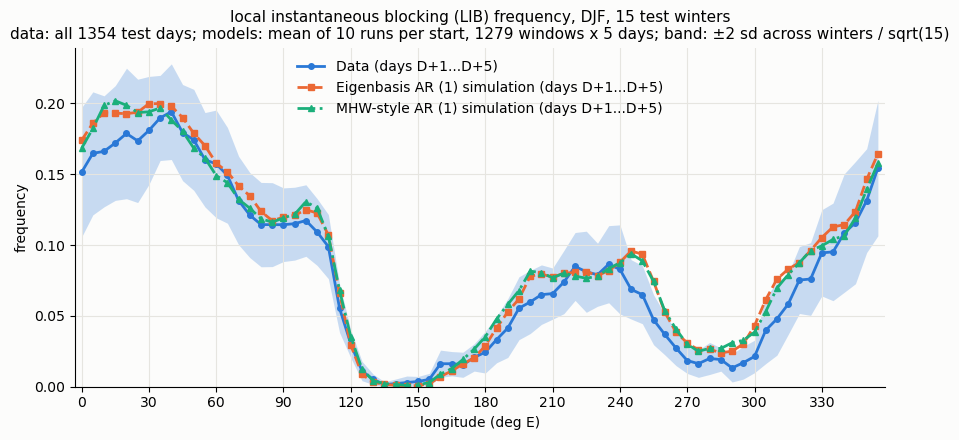

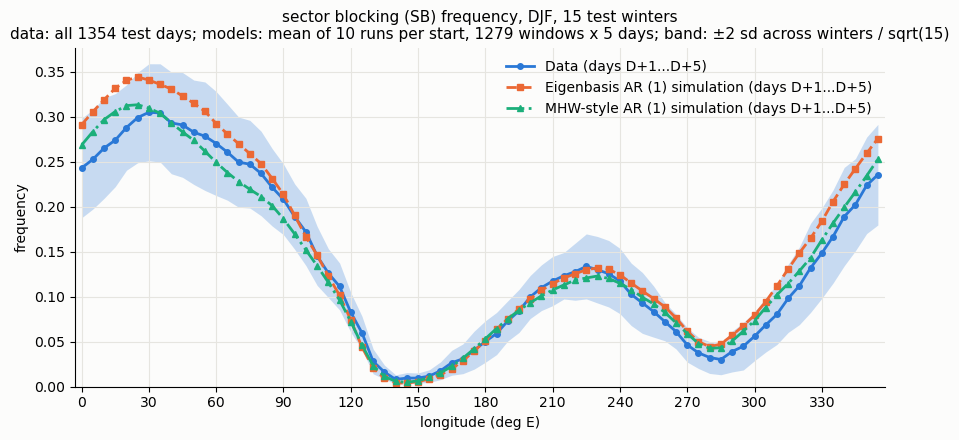

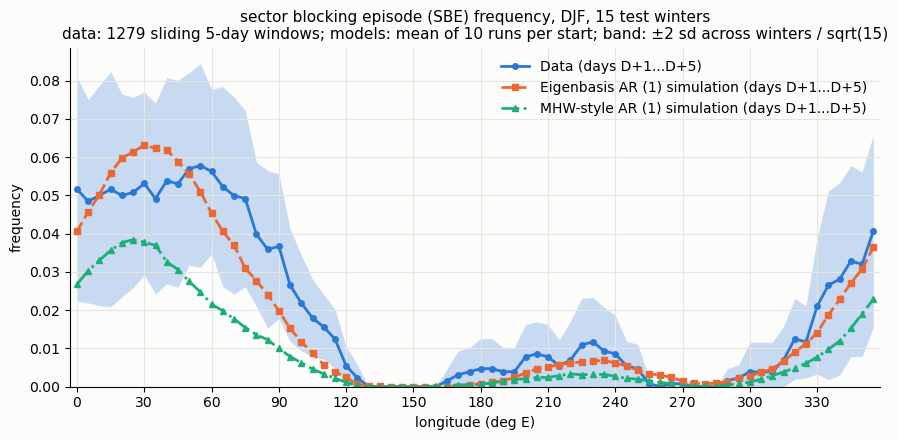

In [18]:
STYLE = {"data":       dict(color="#2a78d6", marker="o", ls="-",  label="Data (days D+1...D+5)"),
         "eigenbasis": dict(color="#eb6834", marker="s", ls="--", label="Eigenbasis AR (1) simulation (days D+1...D+5)"),
         "mhw":        dict(color="#1baf7a", marker="^", ls="-.", label="MHW-style AR (1) simulation (days D+1...D+5)")}
LONG = {"LIB": "local instantaneous blocking (LIB)", "SB": "sector blocking (SB)", "SBE": "sector blocking episode (SBE)"}
SUB  = {"LIB": f"data: all {info['ndays']} test days; models: mean of {NSIM} runs per start, {info['nwin']} windows x {NDAYS} days",
        "SB":  f"data: all {info['ndays']} test days; models: mean of {NSIM} runs per start, {info['nwin']} windows x {NDAYS} days",
        "SBE": f"data: {info['nwin']} {'sliding' if STRIDE == 1 else 'fixed'} {NDAYS}-day windows; models: mean of {NSIM} runs per start"}

for k in ("LIB", "SB", "SBE"):
    fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="#fcfcfb"); ax.set_facecolor("#fcfcfb")
    for m in ["data"] + list(MODELS):
        f, se = df[f"{k}_{m}"].values, df[f"{k}_{m}_se"].values
        if m == "data" or SHOW_MODEL_BAND:
            ax.fill_between(LONS, np.maximum(f - N_SD * se, 0), f + N_SD * se, color=STYLE[m]["color"], alpha=0.25, lw=0)
        ax.plot(LONS, f, ms=4, lw=2, **STYLE[m])
    ax.set_xticks(np.arange(0, 361, 30)); ax.set_xlim(-3, 358); ax.set_ylim(0, None)
    ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("frequency")
    ax.set_title(f"{LONG[k]} frequency, DJF, {nw} test winters\n{SUB[k]}; band: ±{N_SD} sd across winters / sqrt({nw})", fontsize=11)
    ax.grid(True, color="#e6e5e0", lw=0.8)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.legend(frameon=False); fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"{k}_test_data_eigenbasis_mhw.png"), dpi=150)
    plt.show()

## Check against the earlier script outputs (if present)

In [19]:
# Copies of the frequencies.csv written earlier by e1_native_windows.py and mhw_ar1_windows.py (test, sliding, 10 runs).
# The scripts used the same seeds and the same order of random draws, so the MHW curves should agree to rounding;
# the Eigenbasis curves may differ slightly because the scripts stored the basis U in float32.
checks = {"eigenbasis": os.path.join(CODE_DIR, "script_outputs_for_check", "eigenbasis_test_sliding_nsim10_frequencies.csv"),
          "mhw":        os.path.join(CODE_DIR, "script_outputs_for_check", "mhw_test_sliding_nsim10_frequencies.csv")}
for m, path in checks.items():
    if os.path.exists(path):
        old = pd.read_csv(path)
        for k in ("LIB", "SB", "SBE"):
            print(f"{m:10s} {k:3s}: max |notebook - script| = {np.abs(df[f'{k}_{m}'].values - old[f'{k}_model'].values).max():.2e}"
                  f"   (data: {np.abs(df[f'{k}_data'].values - old[f'{k}_data'].values).max():.2e})")
    else:
        print(f"{m}: no earlier output at {path}")

eigenbasis LIB: max |notebook - script| = 5.00e-06   (data: 4.92e-06)
eigenbasis SB : max |notebook - script| = 5.00e-06   (data: 4.94e-06)
eigenbasis SBE: max |notebook - script| = 4.99e-06   (data: 4.85e-06)
mhw        LIB: max |notebook - script| = 4.99e-06   (data: 4.92e-06)
mhw        SB : max |notebook - script| = 4.98e-06   (data: 4.94e-06)
mhw        SBE: max |notebook - script| = 4.94e-06   (data: 4.85e-06)
